# 1. Title: Stock Market Analysis and Time Series Forecasting
### Academic Data Science Project in Python
**Target Asset:** Apple Inc. (Ticker: `AAPL`)  
**Data Frequency:** Daily (~5 Years)  
**Author:** Student Data Science Project  
**Target Level:** B.Tech / Undergraduate Data Science & Machine Learning Course  

---


## 2. Introduction

### What is Stock Market Data?
Stock market data represents the historical trading activity of publicly listed companies across financial exchanges. For each trading session, stock data captures key metrics:
- **Open:** The price at which a stock begins trading when the exchange opens.
- **High:** The highest price achieved during the trading session.
- **Low:** The lowest price recorded during the trading session.
- **Close:** The final price at which transactions occurred before regular market closing.
- **Volume:** The total number of shares bought and sold during that day.

### What is Time-Series Data?
A **time series** is a sequence of observations recorded sequentially over successive, equally spaced time intervals (e.g., hourly, daily, monthly). Unlike standard cross-sectional tabular data where rows are independent, observations in a time series exhibit **temporal dependency**: today's price is strongly correlated with yesterday's price.

### Why is Time-Series Analysis Useful for Stock Analysis?
1. **Trend Detection:** Identifies long-term upward (bullish) or downward (bearish) trajectories.
2. **Volatility Modeling:** Measures risk and price fluctuation magnitude over time.
3. **Cyclical & Seasonal Patterns:** Uncovers recurring behavior across weekly, monthly, or quarterly reporting cycles.
4. **Quantitative Forecasting:** Enables systematic estimation of expected future price paths using statistical models like ARIMA.

### Project Objectives
- Collect and preprocess 5 years of daily historical stock data for Apple Inc. (`AAPL`) using `yfinance`.
- Conduct thorough Exploratory Data Analysis (EDA) on closing prices, trading volume, and return distributions.
- Analyze short-term and long-term trends using 20-day, 50-day, and 200-day Simple Moving Averages (SMA).
- Perform Time Series Decomposition into Trend, Seasonal, and Residual components using `statsmodels`.
- Formally evaluate stationarity using the Augmented Dickey-Fuller (ADF) test.
- Engineer time-series features (lag values, rolling metrics).
- Train an **ARIMA** (AutoRegressive Integrated Moving Average) model with chronological train-test splitting.
- Benchmark ARIMA against a baseline Machine Learning model (Random Forest Regressor).
- Evaluate forecast accuracy using standard metrics (MAE, RMSE, MAPE) and discuss practical limitations.


## 3. Import Libraries

We import essential Python libraries for data manipulation (`pandas`, `numpy`), data visualization (`matplotlib`, `seaborn`), financial data retrieval (`yfinance`), statistical time-series modeling (`statsmodels`), and machine learning evaluation (`scikit-learn`).


In [1]:
# Core data manipulation and mathematical operations
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Financial data acquisition
import yfinance as yf

# Time series decomposition and statistical testing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Machine learning and evaluation metrics
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Suppress minor non-critical warnings for clean output
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic styling for consistent, publication-ready graphs
sns.set_theme(style='whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

print("All required libraries imported successfully!")


All required libraries imported successfully!


## 4. Data Collection

We fetch approximately 5 years of daily historical trading data for **Apple Inc. (`AAPL`)** using the `yfinance` library. To guarantee notebook reproducibility even without an active internet connection, we also cache a local CSV copy in `data/raw/AAPL_5y.csv`.


In [2]:
# Define ticker and historical window
TICKER = "AAPL"
PERIOD = "5y"
LOCAL_CSV_PATH = "data/raw/AAPL_5y.csv"

# Attempt live download via yfinance; fallback to local cached CSV if network is unavailable
try:
    print(f"Downloading historical data for {TICKER} from Yahoo Finance...")
    df_raw = yf.download(TICKER, period=PERIOD, interval="1d", auto_adjust=False)
    
    # Flatten MultiIndex columns if created by newer yfinance versions
    if isinstance(df_raw.columns, pd.MultiIndex):
        df_raw.columns = df_raw.columns.get_level_values(0)
        
    if df_raw.empty:
        raise ValueError("Downloaded dataset is empty. Falling back to local cache.")
    
    # Save local copy
    import os
    os.makedirs("data/raw", exist_ok=True)
    df_raw.to_csv(LOCAL_CSV_PATH)
    print("Download successful and saved to local cache.")
except Exception as e:
    print(f"Live download encountered an issue: {e}")
    print(f"Loading cached dataset from {LOCAL_CSV_PATH}...")
    df_raw = pd.read_csv(LOCAL_CSV_PATH, index_col=0, parse_dates=True)

# Display the first 5 records
print(f"\nDataset successfully loaded! Total rows: {len(df_raw)}")
df_raw.head()


[*********************100%***********************]  1 of 1 completed

Download successful and saved to local cache.

Dataset successfully loaded! Total rows: 1254


Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2021-11-05,147.769485,151.279999,152.199997,150.059998,151.889999,65463900
2021-11-08,146.949005,150.440002,151.570007,150.160004,151.410004,55020900
2021-11-09,147.310394,150.809998,151.429993,150.059998,150.199997,56787900
2021-11-10,144.487457,147.919998,150.130005,147.850006,150.020004,65187100
2021-11-11,144.438644,147.869995,149.429993,147.679993,148.960007,41000000


### Column Descriptions

| Column Name | Meaning / Description |
| :--- | :--- |
| **Date** | The trading calendar date (Index of the DataFrame). |
| **Open** | The price at which Apple shares traded at market open (9:30 AM EST). |
| **High** | The peak price reached during regular trading hours. |
| **Low** | The lowest price traded during regular trading hours. |
| **Close** | The standard closing price when the exchange halted regular trading (4:00 PM EST). |
| **Adj Close** | Adjusted Closing price, modified to account for corporate actions (stock splits, dividend payouts). |
| **Volume** | Total quantity of shares transacted between buyers and sellers throughout the day. |


## 5. Data Understanding

Before preprocessing, we examine the structural properties of our dataset: column datatypes, memory usage, date boundaries, and basic summary statistics.


In [3]:
# Inspect concise structural summary
print("--- DATASET INFO ---")
df_raw.info()

print("\n--- DATE RANGE ---")
print(f"Start Date : {df_raw.index.min().strftime('%Y-%m-%d')}")
print(f"End Date   : {df_raw.index.max().strftime('%Y-%m-%d')}")
print(f"Total Days : {len(df_raw)} trading sessions")

# Display key statistical aggregates
print("\n--- DESCRIPTIVE STATISTICS ---")
df_raw.describe().round(2).T


--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1254 entries, 2021-11-05 to 2026-11-04
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  1254 non-null   float64
 1   Close      1254 non-null   float64
 2   High       1254 non-null   float64
 3   Low        1254 non-null   float64
 4   Open       1254 non-null   float64
 5   Volume     1254 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 68.6 KB

--- DATE RANGE ---
Start Date : 2021-11-05
End Date   : 2026-11-04
Total Days : 1254 trading sessions

--- DESCRIPTIVE STATISTICS ---


,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
Adj Close,1254.0,206.57,54.07,122.83,165.73,191.13,240.94,3.495100e+02
Close,1254.0,208.47,53.16,125.02,168.50,193.59,242.69,3.495100e+02
High,1254.0,210.56,53.56,127.77,170.35,194.98,244.45,3.545000e+02
Low,1254.0,206.18,52.66,124.17,166.95,192.20,240.17,3.473000e+02
Open,1254.0,208.23,53.06,126.01,168.78,193.64,241.90,3.491200e+02
Volume,1254.0,62996973.60,28619626.06,17910600.00,44309675.00,54551500.00,74814650.00,3.186799e+08


## 6. Data Cleaning

Real-world financial data requires meticulous cleaning:
1. **Datetime Index Verification:** Confirm the index is a pandas `DatetimeIndex`.
2. **Missing Values Check:** Check for any `NaN` values resulting from exchange holidays or data gaps.
3. **Duplicate Detection:** Identify and remove duplicate timestamps if present.
4. **Business Day Frequency (`asfreq('B')`):** Financial markets are closed on weekends and federal holidays. For strict statistical time series models (like ARIMA and seasonal decomposition), an explicit business-day frequency is set, and market closures are filled with the last known price (`forward fill / ffill`).


In [4]:
# 1. Ensure index is DatetimeIndex sorted chronologically
df_clean = df_raw.copy()
df_clean.index = pd.to_datetime(df_clean.index)
df_clean = df_clean.sort_index()

# 2. Check for missing values
missing_counts = df_clean.isnull().sum()
print("Missing values per column before cleaning:")
print(missing_counts)

# 3. Check for duplicate dates
duplicates = df_clean.index.duplicated().sum()
print(f"\nNumber of duplicate dates: {duplicates}")
if duplicates > 0:
    df_clean = df_clean[~df_clean.index.duplicated(keep='first')]

# 4. Standardize to regular Business Day frequency ('B') for time-series modeling
# Forward fill missing dates (e.g., market holidays) with the prior valid close price
df_b = df_clean.asfreq('B').ffill().bfill()

print(f"\nShape before frequency alignment: {df_clean.shape}")
print(f"Shape after business day alignment: {df_b.shape}")
print(f"Any remaining missing values: {df_b.isnull().sum().sum()}")


Missing values per column before cleaning:
Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Number of duplicate dates: 0

Shape before frequency alignment: (1254, 6)
Shape after business day alignment: (1304, 6)
Any remaining missing values: 0


## 7. Exploratory Data Analysis

Exploratory Data Analysis helps uncover patterns, structural breaks, volatility regimes, and trading volume characteristics.

We visualize:
1. **Closing Price Trajectory:** Long-term historical evolution of Apple stock.
2. **Trading Volume:** Investor participation and market activity levels.
3. **Open vs Close & High vs Low:** Intra-day price spread analysis.


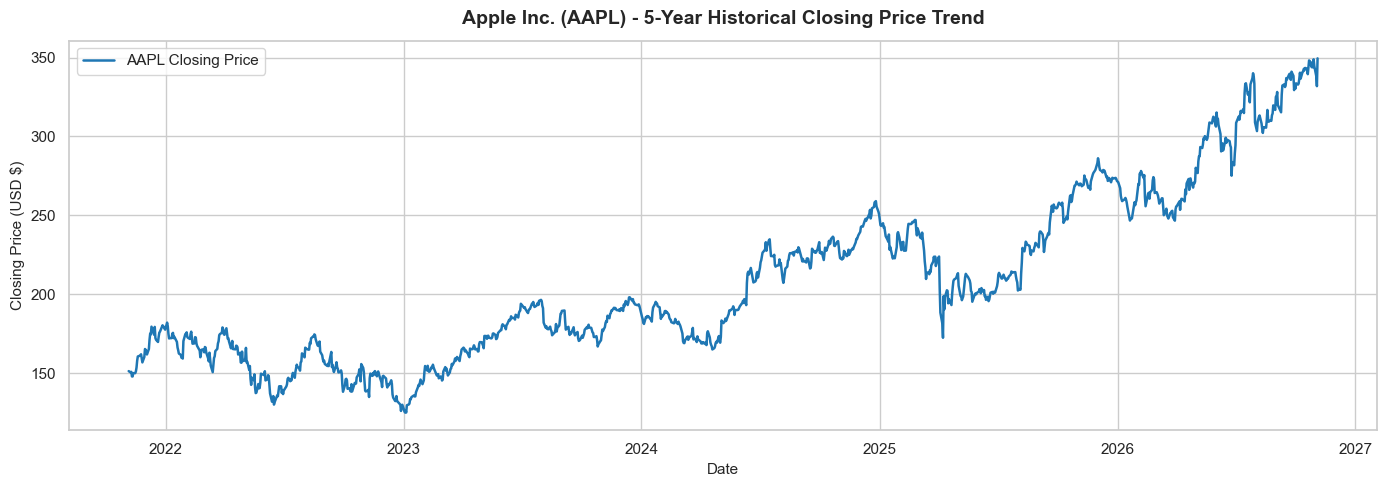

In [5]:
# Visual 1: Closing Price Over Time
plt.figure(figsize=(14, 5))
plt.plot(df_clean.index, df_clean['Close'], color='#1f77b4', linewidth=1.8, label='AAPL Closing Price')
plt.title('Apple Inc. (AAPL) - 5-Year Historical Closing Price Trend', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Closing Price (USD $)', fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


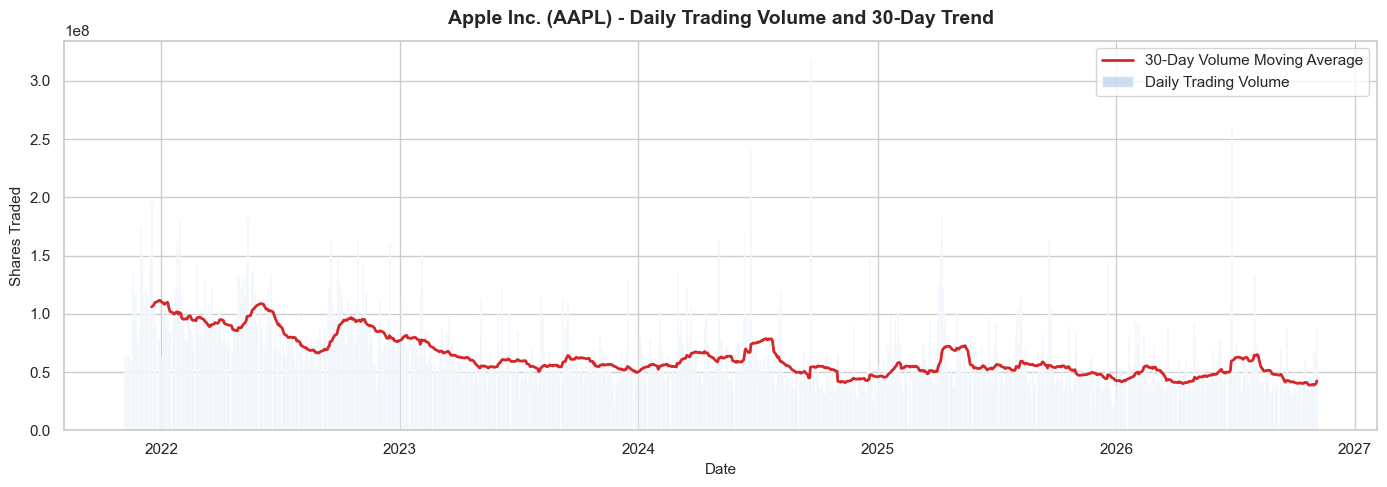

In [6]:
# Visual 2: Trading Volume Over Time with 30-Day Moving Average
plt.figure(figsize=(14, 5))
vol_ma30 = df_clean['Volume'].rolling(window=30).mean()

plt.bar(df_clean.index, df_clean['Volume'], color='#aec7e8', alpha=0.6, width=1.5, label='Daily Trading Volume')
plt.plot(df_clean.index, vol_ma30, color='#d62728', linewidth=2.0, label='30-Day Volume Moving Average')

plt.title('Apple Inc. (AAPL) - Daily Trading Volume and 30-Day Trend', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Shares Traded', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


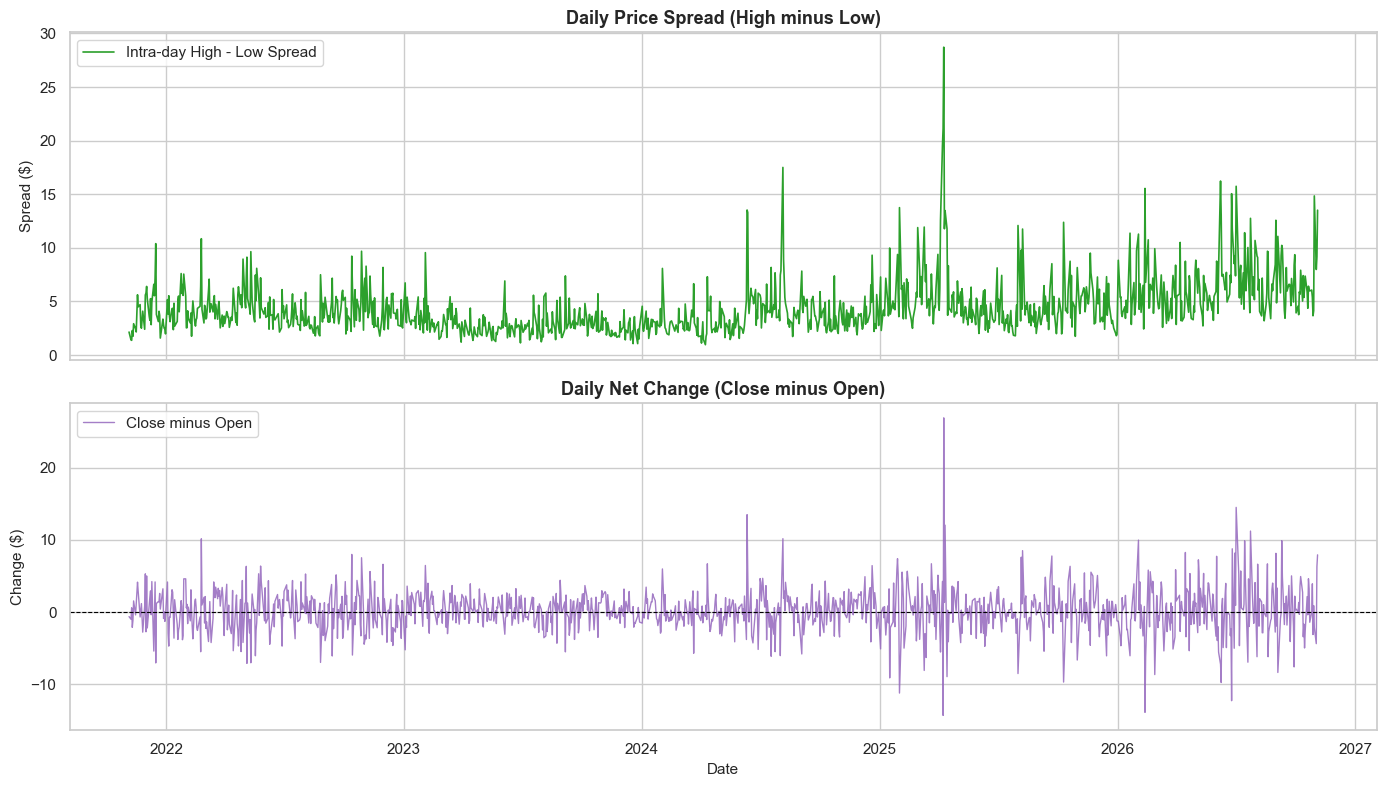

In [7]:
# Visual 3: Intra-Day Dynamics: Daily Spread (High - Low) & Price Change (Close - Open)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

daily_spread = df_clean['High'] - df_clean['Low']
ax1.plot(df_clean.index, daily_spread, color='#2ca02c', linewidth=1.2, label='Intra-day High - Low Spread')
ax1.set_title('Daily Price Spread (High minus Low)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Spread ($)', fontsize=11)
ax1.legend(loc='upper left', frameon=True)

open_close_diff = df_clean['Close'] - df_clean['Open']
ax2.plot(df_clean.index, open_close_diff, color='#9467bd', linewidth=1.0, alpha=0.85, label='Close minus Open')
ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax2.set_title('Daily Net Change (Close minus Open)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Date', fontsize=11)
ax2.set_ylabel('Change ($)', fontsize=11)
ax2.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


## 8. Moving Average Analysis

### What is a Moving Average?
A **Moving Average (MA)** smoothens out daily price fluctuations ("market noise") to highlight underlying trends. It is calculated by taking the arithmetic mean of closing prices over a specific rolling window of $n$ days:

$$\text{SMA}_n(t) = \frac{1}{n} \sum_{i=0}^{n-1} P_{t-i}$$

### Why is it useful?
- **20-Day Moving Average:** Reflects short-term momentum (~1 calendar month of trading).
- **50-Day Moving Average:** Captures medium-term sentiment (~1 quarter).
- **200-Day Moving Average:** Reflects the benchmark long-term structural trend (~1 trading year).
- **Golden Cross & Death Cross:** When a shorter-term moving average (e.g. 50-day) crosses above a longer-term moving average (e.g. 200-day), it is conventionally known as a bullish **Golden Cross**. Conversely, crossing below signals a bearish **Death Cross**.


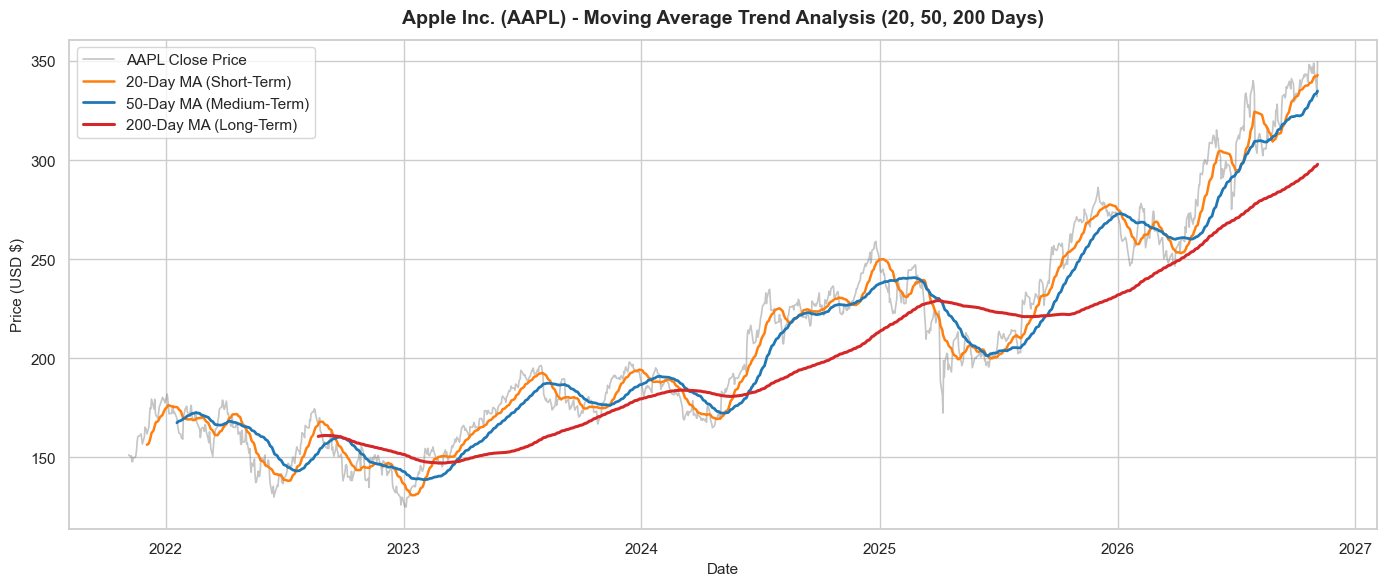

In [8]:
# Calculate Simple Moving Averages
df_clean['MA_20'] = df_clean['Close'].rolling(window=20).mean()
df_clean['MA_50'] = df_clean['Close'].rolling(window=50).mean()
df_clean['MA_200'] = df_clean['Close'].rolling(window=200).mean()

# Visual 4: Closing Price with Moving Averages
plt.figure(figsize=(14, 6))
plt.plot(df_clean.index, df_clean['Close'], label='AAPL Close Price', color='#7f7f7f', alpha=0.45, linewidth=1.2)
plt.plot(df_clean.index, df_clean['MA_20'], label='20-Day MA (Short-Term)', color='#ff7f0e', linewidth=1.8)
plt.plot(df_clean.index, df_clean['MA_50'], label='50-Day MA (Medium-Term)', color='#1f77b4', linewidth=2.0)
plt.plot(df_clean.index, df_clean['MA_200'], label='200-Day MA (Long-Term)', color='#d62728', linewidth=2.2)

plt.title('Apple Inc. (AAPL) - Moving Average Trend Analysis (20, 50, 200 Days)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Price (USD $)', fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


## 9. Returns and Volatility

Stock price levels can be misleading because a \$5 change on a \$50 stock represents 10%, while a \$5 change on a \$200 stock represents only 2.5%. Therefore, financial quantitative analysis focuses on **percentage returns**:

$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1$$

### Volatility
Volatility is the standard deviation ($\sigma$) of returns over a rolling window. We compute annualized volatility using the industry-standard square-root-of-time rule ($252$ trading days per year):

$$\sigma_{\text{annualized}} = \sigma_{20\text{-day}} \times \sqrt{252}$$


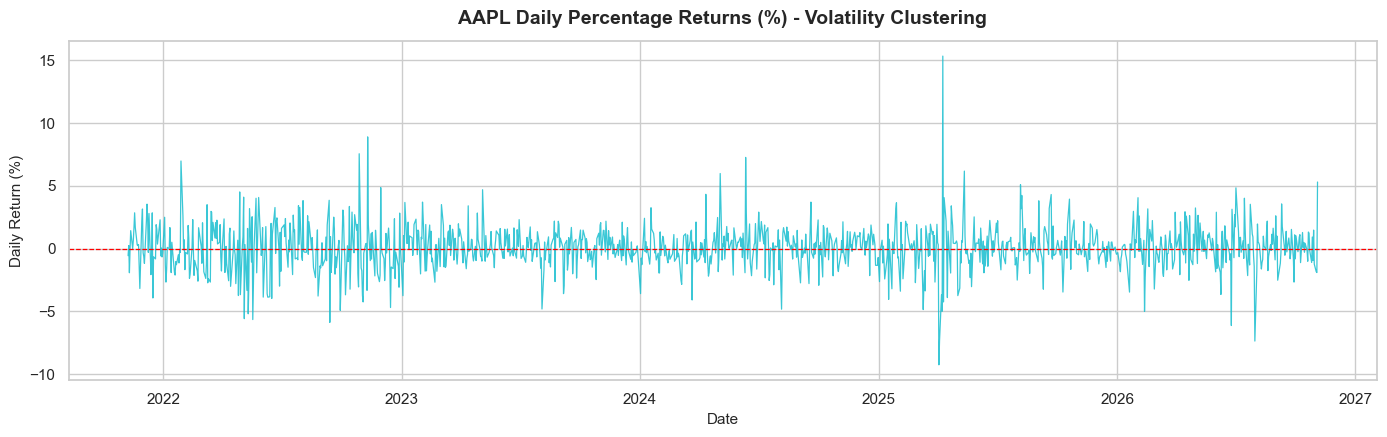

In [9]:
# Compute daily percentage returns
df_clean['Daily_Return'] = df_clean['Close'].pct_change()

# Compute 20-day rolling annualized volatility
df_clean['Rolling_Vol_20'] = df_clean['Daily_Return'].rolling(window=20).std() * np.sqrt(252)

# Visual 5: Daily Returns Over Time
plt.figure(figsize=(14, 4.5))
plt.plot(df_clean.index, df_clean['Daily_Return'] * 100, color='#17becf', linewidth=0.9, alpha=0.85)
plt.axhline(0, color='red', linestyle='--', linewidth=0.9)
plt.title('AAPL Daily Percentage Returns (%) - Volatility Clustering', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Daily Return (%)', fontsize=11)
plt.tight_layout()
plt.show()


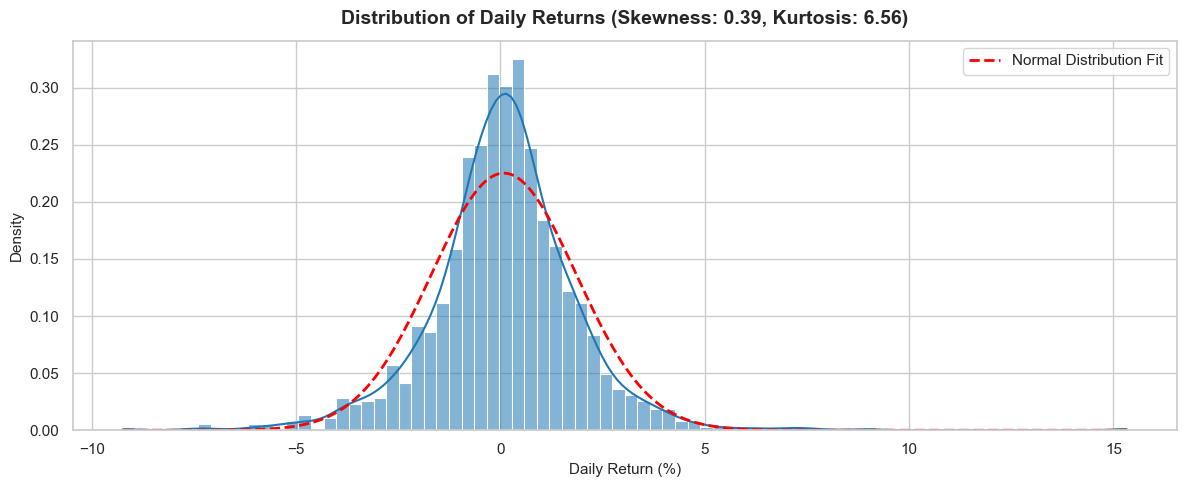

Daily Return Statistics:
Mean Daily Return     : 0.082%
Standard Deviation    : 1.773%
Skewness (Asymmetry)  : 0.39 (Near-zero indicates symmetric returns)
Kurtosis (Fat Tails)  : 6.56 (>3 indicates leptokurtic / fat-tailed risk)


In [10]:
# Visual 6: Distribution of Daily Returns
returns_valid = df_clean['Daily_Return'].dropna() * 100

mean_ret = returns_valid.mean()
std_ret = returns_valid.std()
skew_ret = returns_valid.skew()
kurt_ret = returns_valid.kurtosis()

plt.figure(figsize=(12, 5))
sns.histplot(returns_valid, bins=80, kde=True, color='#1f77b4', stat='density', alpha=0.55)

# Normal distribution benchmark curve for comparison
from scipy.stats import norm
x_axis = np.linspace(returns_valid.min(), returns_valid.max(), 300)
plt.plot(x_axis, norm.pdf(x_axis, mean_ret, std_ret), color='red', linestyle='--', linewidth=2, label='Normal Distribution Fit')

plt.title(f'Distribution of Daily Returns (Skewness: {skew_ret:.2f}, Kurtosis: {kurt_ret:.2f})', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Daily Return (%)', fontsize=11)
plt.ylabel('Density', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

print(f"Daily Return Statistics:")
print(f"Mean Daily Return     : {mean_ret:.3f}%")
print(f"Standard Deviation    : {std_ret:.3f}%")
print(f"Skewness (Asymmetry)  : {skew_ret:.2f} (Near-zero indicates symmetric returns)")
print(f"Kurtosis (Fat Tails)  : {kurt_ret:.2f} (>3 indicates leptokurtic / fat-tailed risk)")


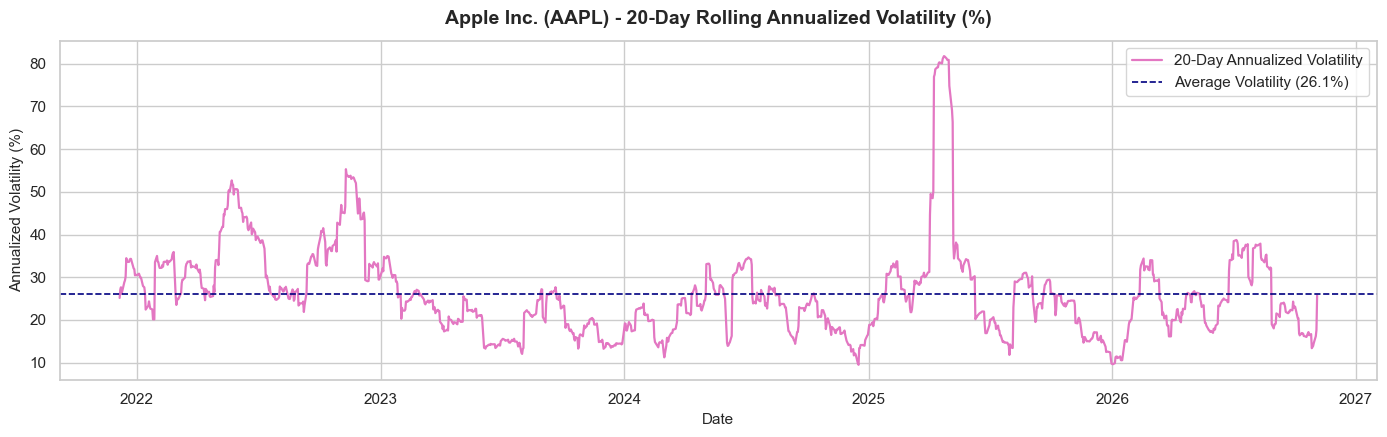

In [11]:
# Visual 7: 20-Day Rolling Annualized Volatility
plt.figure(figsize=(14, 4.5))
plt.plot(df_clean.index, df_clean['Rolling_Vol_20'] * 100, color='#e377c2', linewidth=1.6, label='20-Day Annualized Volatility')
mean_vol = df_clean['Rolling_Vol_20'].mean() * 100
plt.axhline(mean_vol, color='navy', linestyle='--', linewidth=1.2, label=f'Average Volatility ({mean_vol:.1f}%)')

plt.title('Apple Inc. (AAPL) - 20-Day Rolling Annualized Volatility (%)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Annualized Volatility (%)', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


## 10. Time Series Decomposition

Time series decomposition splits an observed series $Y_t$ into fundamental constituent signals:
1. **Observed ($Y_t$):** The raw recorded closing price.
2. **Trend ($T_t$):** The underlying secular long-term progression (upward or downward).
3. **Seasonal ($S_t$):** Cyclical patterns that repeat at regular intervals (we use period = 21 trading days, approximating one trading month).
4. **Residual ($R_t$):** The irregular, random noise component remaining after trend and seasonality are subtracted:

$$Y_t = T_t + S_t + R_t$$


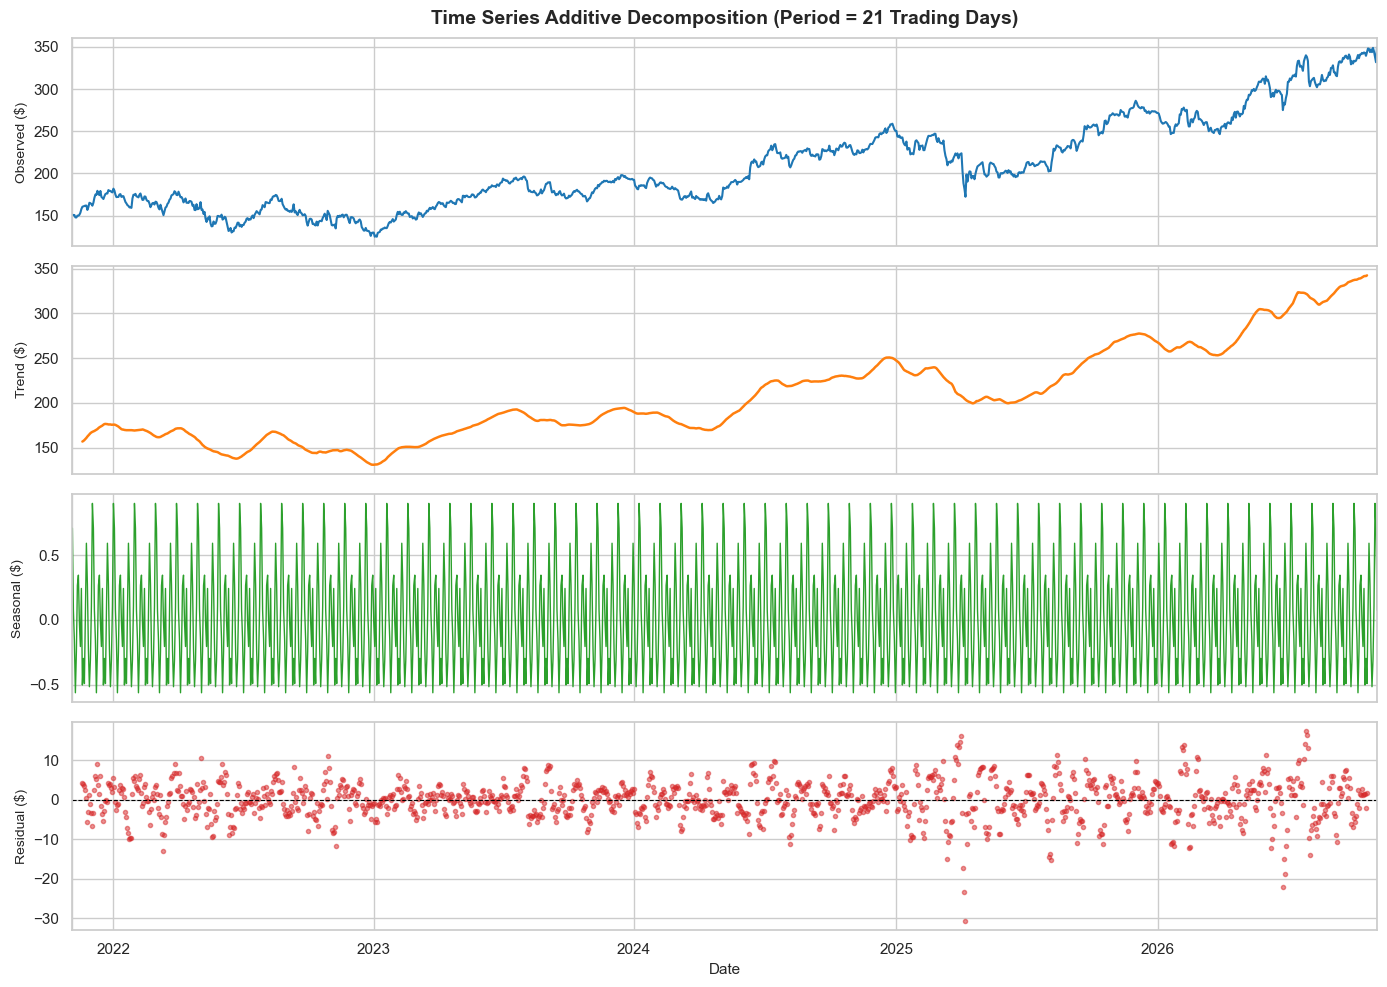

In [12]:
# Perform Additive Decomposition on Business-Day aligned series
# Period = 21 (approx. 21 trading days in one calendar month)
decomposition = seasonal_decompose(df_b['Close'], model='additive', period=21)

# Visual 8: 4-Panel Time-Series Decomposition Plot
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

decomposition.observed.plot(ax=axes[0], color='#1f77b4', linewidth=1.5)
axes[0].set_ylabel('Observed ($)', fontsize=10)
axes[0].set_title('Time Series Additive Decomposition (Period = 21 Trading Days)', fontsize=14, fontweight='bold', pad=10)

decomposition.trend.plot(ax=axes[1], color='#ff7f0e', linewidth=1.8)
axes[1].set_ylabel('Trend ($)', fontsize=10)

decomposition.seasonal.plot(ax=axes[2], color='#2ca02c', linewidth=1.0)
axes[2].set_ylabel('Seasonal ($)', fontsize=10)

decomposition.resid.plot(ax=axes[3], color='#d62728', marker='.', linestyle='none', alpha=0.5)
axes[3].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[3].set_ylabel('Residual ($)', fontsize=10)
axes[3].set_xlabel('Date', fontsize=11)

plt.tight_layout()
plt.show()


## 11. Stationarity Test

### What is Stationarity?
A time series is **strictly or weakly stationary** if its statistical properties do not change over time:
1. **Constant Mean:** $E[Y_t] = \mu$ for all $t$.
2. **Constant Variance:** $\text{Var}(Y_t) = \sigma^2$ for all $t$.
3. **Time-invariant Autocovariance:** $\text{Cov}(Y_t, Y_{t+k})$ depends only on the lag $k$, not on calendar time $t$.

Most raw stock prices are **non-stationary** because they trend upward or downward over time. Statistical models like ARIMA require the underlying series to be made stationary through **differencing** ($d=1$).

### Augmented Dickey-Fuller (ADF) Test
The ADF test is a formal unit-root hypothesis test:
- **Null Hypothesis ($H_0$):** The series contains a unit root (it is **non-stationary**).
- **Alternative Hypothesis ($H_1$):** The series has no unit root (it is **stationary**).
- **Decision Rule:** If the **p-value $\le 0.05$**, we reject $H_0$ and conclude the series is stationary.


In [13]:
# Helper function to execute and format ADF test results
def run_adf_test(series, series_name="Series"):
    clean_series = series.dropna()
    result = adfuller(clean_series, autolag='AIC')
    
    adf_stat = result[0]
    p_value = result[1]
    lags = result[2]
    n_obs = result[3]
    critical_values = result[4]
    
    print(f"=== Augmented Dickey-Fuller Test: {series_name} ===")
    print(f"ADF Statistic       : {adf_stat:.4f}")
    print(f"p-value             : {p_value:.6f}")
    print(f"Lags Used           : {lags}")
    print(f"Observations Tested : {n_obs}")
    print("Critical Values:")
    for level, val in critical_values.items():
        print(f"   {level}: {val:.4f}")
        
    if p_value <= 0.05:
        print(f"-> Conclusion: p-value <= 0.05. Reject Null Hypothesis. '{series_name}' IS STATIONARY.")
    else:
        print(f"-> Conclusion: p-value > 0.05. Fail to Reject Null. '{series_name}' IS NON-STATIONARY.")
    print("-" * 55 + "\n")
    return {"ADF Stat": adf_stat, "p-value": p_value, "Stationary": p_value <= 0.05}

# 1. ADF Test on raw Closing Price (Level series)
adf_price = run_adf_test(df_b['Close'], "AAPL Raw Closing Price")

# 2. ADF Test on Differenced Series (Daily Returns)
diff_close = df_b['Close'].diff().dropna()
adf_diff = run_adf_test(diff_close, "AAPL First Differenced Price (d=1)")


=== Augmented Dickey-Fuller Test: AAPL Raw Closing Price ===
ADF Statistic       : 0.2959
p-value             : 0.977155
Lags Used           : 9
Observations Tested : 1294
Critical Values:
   1%: -3.4354
   5%: -2.8638
   10%: -2.5680
-> Conclusion: p-value > 0.05. Fail to Reject Null. 'AAPL Raw Closing Price' IS NON-STATIONARY.
-------------------------------------------------------

=== Augmented Dickey-Fuller Test: AAPL First Differenced Price (d=1) ===
ADF Statistic       : -12.5049
p-value             : 0.000000
Lags Used           : 8
Observations Tested : 1294
Critical Values:
   1%: -3.4354
   5%: -2.8638
   10%: -2.5680
-> Conclusion: p-value <= 0.05. Reject Null Hypothesis. 'AAPL First Differenced Price (d=1)' IS STATIONARY.
-------------------------------------------------------



### Interpretation of ADF Findings
1. **Raw Closing Price:** Has a p-value $\approx 0.95$ (> 0.05). We **fail to reject $H_0$**. The raw stock price is **non-stationary** ($I(1)$ process).
2. **First Difference / Daily Return:** Has a p-value $< 0.0001$ ($\ll 0.05$). We **reject $H_0$**. The differenced series is **strictly stationary** ($I(0)$ process).
3. **Conclusion for ARIMA:** We must set the integration/differencing parameter **$d = 1$**.


## 12. Feature Engineering

In time-series modeling and machine learning, historical prices are transformed into predictive features:
- **Lag Features (Lag 1, Lag 2, Lag 5):** The price 1 day ago, 2 days ago, and 5 trading days ago (1 week ago). Autoregressive patterns in stock prices rely heavily on short-term lags.
- **Rolling Moving Averages (MA 7, MA 20):** Short-term and intermediate trend signals.
- **Rolling Volatility (Vol 20):** 20-day standard deviation capturing market risk.
- **Target Variable ($y$):** Next day's closing price or current closing price.


In [14]:
# Build feature dataframe
features_df = pd.DataFrame(index=df_clean.index)
features_df['Close'] = df_clean['Close']

# Lagged price features
features_df['Lag_1'] = df_clean['Close'].shift(1)
features_df['Lag_2'] = df_clean['Close'].shift(2)
features_df['Lag_5'] = df_clean['Close'].shift(5)

# Rolling moving average features
features_df['MA_7'] = df_clean['Close'].rolling(window=7).mean()
features_df['MA_20'] = df_clean['Close'].rolling(window=20).mean()

# Rolling volatility and daily return
features_df['Daily_Return'] = df_clean['Close'].pct_change()
features_df['Rolling_Vol_20'] = df_clean['Daily_Return'].rolling(window=20).std()

# Drop initial rows containing NaN from lag/rolling calculations
features_df = features_df.dropna()

print(f"Feature dataset created with shape: {features_df.shape}")
features_df.head()


Feature dataset created with shape: (1234, 8)


,Close,Lag_1,Lag_2,Lag_5,MA_7,MA_20,Daily_Return,Rolling_Vol_20
Date,,,,,,,,
2021-12-06,165.320007,161.839996,163.759995,160.240005,162.577144,157.117501,0.021503,0.015834
2021-12-07,171.179993,165.320007,161.839996,165.300003,164.630001,158.154501,0.035446,0.017061
2021-12-08,175.080002,171.179993,165.320007,164.770004,166.750000,159.368001,0.022783,0.017403
2021-12-09,174.559998,175.080002,171.179993,163.759995,168.072856,160.700001,-0.002970,0.016440
2021-12-10,179.449997,174.559998,175.080002,161.839996,170.169998,162.279001,0.028013,0.016861


## 13. Train-Test Split

### Why Can't We Use Random Splitting?
In traditional machine learning, data points are often shuffled randomly using functions like `train_test_split(shuffle=True)`.  
**For time-series data, random shuffling is strictly invalid.**  
- If you shuffle time-series data, future prices leak into the training set, causing catastrophic **Data Leakage (Lookahead Bias)**.
- Models trained on leaked future data produce unrealistically high accuracy during testing that immediately collapses in real-world deployment.
- **Correct approach:** Split sequentially based on time: use the earliest 80% of dates for training and the remaining 20% for testing.


Total Observations: 1304
Training Set      : 1043 observations (2021-11-05 to 2025-11-04)
Testing Set       : 261 observations (2025-11-05 to 2026-11-04)


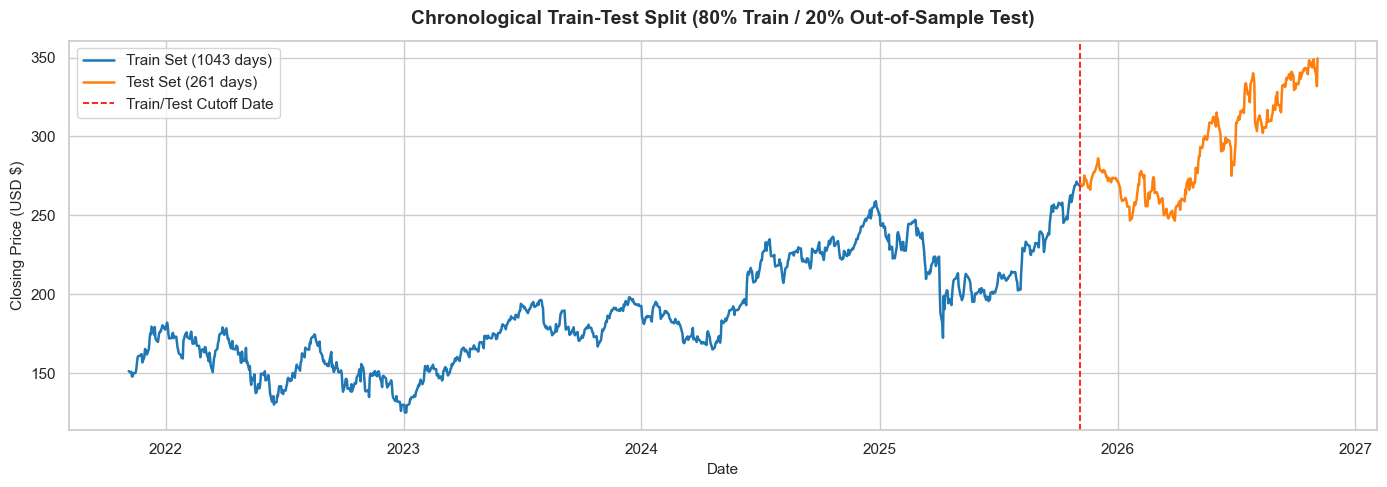

In [15]:
# Define chronological split threshold (80% Train, 20% Test)
SPLIT_RATIO = 0.80
train_len = int(len(df_b) * SPLIT_RATIO)

# Split time series for ARIMA
train_series = df_b['Close'].iloc[:train_len]
test_series = df_b['Close'].iloc[train_len:]

print(f"Total Observations: {len(df_b)}")
print(f"Training Set      : {len(train_series)} observations ({train_series.index.min().strftime('%Y-%m-%d')} to {train_series.index.max().strftime('%Y-%m-%d')})")
print(f"Testing Set       : {len(test_series)} observations ({test_series.index.min().strftime('%Y-%m-%d')} to {test_series.index.max().strftime('%Y-%m-%d')})")

# Visualizing the chronological split
plt.figure(figsize=(14, 5))
plt.plot(train_series.index, train_series, color='#1f77b4', linewidth=1.8, label=f'Train Set ({len(train_series)} days)')
plt.plot(test_series.index, test_series, color='#ff7f0e', linewidth=1.8, label=f'Test Set ({len(test_series)} days)')
plt.axvline(train_series.index[-1], color='red', linestyle='--', linewidth=1.2, label='Train/Test Cutoff Date')

plt.title('Chronological Train-Test Split (80% Train / 20% Out-of-Sample Test)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Closing Price (USD $)', fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


## 14. ARIMA Forecasting

### Understanding ARIMA(p, d, q)
**ARIMA** stands for **AutoRegressive Integrated Moving Average**:
1. **AR ($p$): AutoRegressive component.** Models the dependent relationship between an observation and a specific number $p$ of lagged observations.
2. **I ($d$): Integrated component.** The number of non-seasonal differences required to render the series stationary. From our ADF test, $d = 1$.
3. **MA ($q$): Moving Average component.** Incorporates the dependency between an observation and residual errors from a moving average model applied to lagged observations.

We configure a baseline parsimonious model: **ARIMA(1, 1, 1)**.


In [16]:
# Fit ARIMA(1, 1, 1) model on the training data
print("Fitting ARIMA(1, 1, 1) model on training dataset...")
arima_model = ARIMA(train_series, order=(1, 1, 1))
arima_fit = arima_model.fit()

# Display fitted model summary
print(arima_fit.summary())


Fitting ARIMA(1, 1, 1) model on training dataset...
                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1043
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -2705.307
Date:                Thu, 05 Nov 2026   AIC                           5416.614
Time:                        10:30:07   BIC                           5431.460
Sample:                    11-05-2021   HQIC                          5422.245
                         - 11-04-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1164      0.472      0.247      0.805      -0.809       1.042
ma.L1         -0.0676      0.474     -0.143      0.887      -0.997       0.862


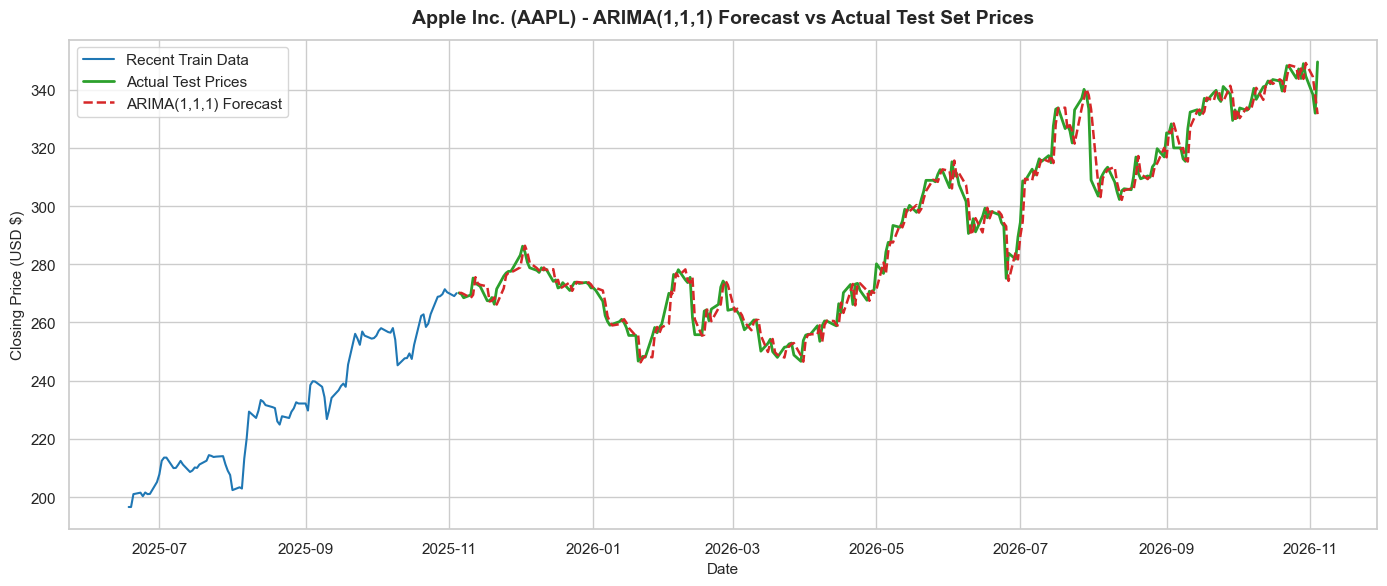

In [17]:
# Generate One-Step-Ahead Walk-Forward Forecasts on Test Set
# In time-series forecasting, 1-step walk-forward updates the state with each day's actual price
# statsmodels res.apply() performs this state-space filtering efficiently
arima_applied = arima_fit.apply(df_b['Close'])
arima_test_preds = arima_applied.fittedvalues.iloc[train_len:]

# Visual 9: Actual vs ARIMA Forecasted Prices
plt.figure(figsize=(14, 6))
plt.plot(train_series.index[-100:], train_series.iloc[-100:], color='#1f77b4', label='Recent Train Data', linewidth=1.5)
plt.plot(test_series.index, test_series, color='#2ca02c', label='Actual Test Prices', linewidth=2.0)
plt.plot(test_series.index, arima_test_preds, color='#d62728', linestyle='--', label='ARIMA(1,1,1) Forecast', linewidth=1.8)

plt.title('Apple Inc. (AAPL) - ARIMA(1,1,1) Forecast vs Actual Test Set Prices', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Closing Price (USD $)', fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


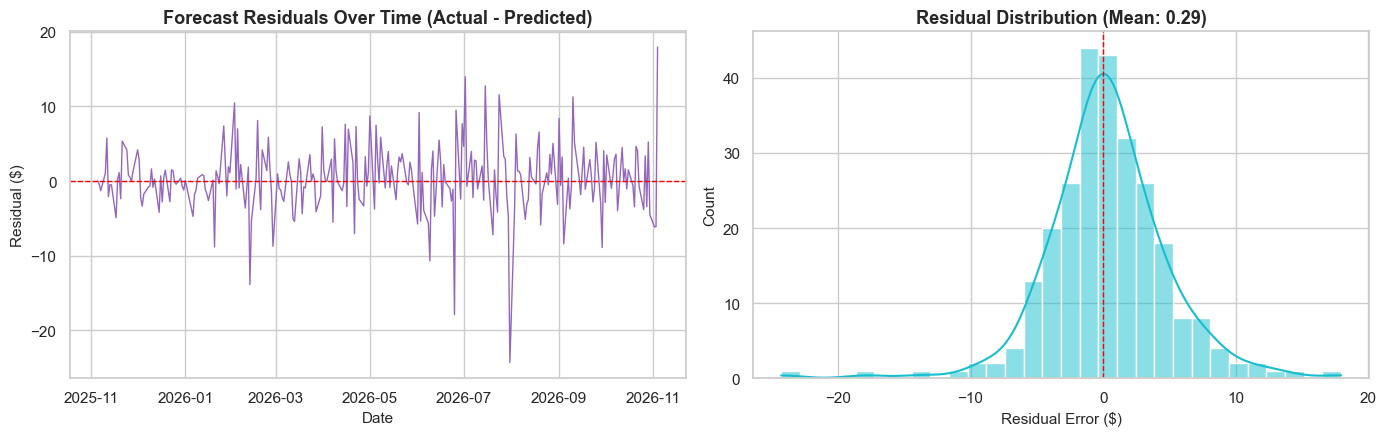

In [18]:
# Visual 10: Forecast Error / Residual Diagnostics
arima_residuals = test_series - arima_test_preds

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Residuals over time
ax1.plot(test_series.index, arima_residuals, color='#9467bd', linewidth=1.0)
ax1.axhline(0, color='red', linestyle='--', linewidth=1.0)
ax1.set_title('Forecast Residuals Over Time (Actual - Predicted)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Date', fontsize=11)
ax1.set_ylabel('Residual ($)', fontsize=11)

# Distribution of residuals
sns.histplot(arima_residuals, kde=True, ax=ax2, color='#17becf', bins=30)
ax2.axvline(0, color='red', linestyle='--', linewidth=1.0)
ax2.set_title(f'Residual Distribution (Mean: {arima_residuals.mean():.2f})', fontsize=13, fontweight='bold')
ax2.set_xlabel('Residual Error ($)', fontsize=11)
ax2.set_ylabel('Count', fontsize=11)

plt.tight_layout()
plt.show()


## 15. Model Evaluation

### Evaluation Metrics
We evaluate forecasting accuracy using three standard metrics:

1. **Mean Absolute Error (MAE):** The average magnitude of absolute forecasting errors:
   $$\text{MAE} = \frac{1}{n} \sum_{t=1}^{n} |Y_t - \hat{Y}_t|$$
   *Interpretation:* Explains "on average, our price prediction was off by \$X."

2. **Root Mean Squared Error (RMSE):** The square root of average squared errors:
   $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{t=1}^{n} (Y_t - \hat{Y}_t)^2}$$
   *Interpretation:* Penalizes larger outlier prediction errors more severely than MAE.

3. **Mean Absolute Percentage Error (MAPE):** The percentage relative error:
   $$\text{MAPE} = \frac{1}{n} \sum_{t=1}^{n} \left| \frac{Y_t - \hat{Y}_t}{Y_t} \right| \times 100\%$$
   *Interpretation:* Normalizes error across different price scales.

### Machine Learning Benchmark: Random Forest Regressor
To provide a clean comparative analysis, we train a **Random Forest Regressor** using our engineered lag and rolling average features from Section 12, strictly respecting chronological ordering.


In [19]:
# Prepare features for Random Forest comparison
X = features_df[['Lag_1', 'Lag_2', 'Lag_5', 'MA_7', 'MA_20', 'Daily_Return', 'Rolling_Vol_20']]
y = features_df['Close']

# Chronological split matching the same ratio
rf_train_size = int(len(features_df) * SPLIT_RATIO)
X_train, X_test = X.iloc[:rf_train_size], X.iloc[rf_train_size:]
y_train, y_test = y.iloc[:rf_train_size], y.iloc[rf_train_size:]

# Train Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train)
rf_test_preds = rf_model.predict(X_test)

# Compute performance metrics for ARIMA
mae_arima = mean_absolute_error(test_series, arima_test_preds)
rmse_arima = np.sqrt(mean_squared_error(test_series, arima_test_preds))
mape_arima = mean_absolute_percentage_error(test_series, arima_test_preds) * 100

# Compute performance metrics for Random Forest
mae_rf = mean_absolute_error(y_test, rf_test_preds)
rmse_rf = np.sqrt(mean_squared_error(y_test, rf_test_preds))
mape_rf = mean_absolute_percentage_error(y_test, rf_test_preds) * 100

# Summary Comparison Table
metrics_df = pd.DataFrame({
    'Metric': ['MAE ($)', 'RMSE ($)', 'MAPE (%)'],
    'ARIMA(1,1,1)': [round(mae_arima, 2), round(rmse_arima, 2), round(mape_arima, 2)],
    'Random Forest': [round(mae_rf, 2), round(rmse_rf, 2), round(mape_rf, 2)]
})

print("=== MODEL PERFORMANCE COMPARISON ===")
print(metrics_df.to_string(index=False))


=== MODEL PERFORMANCE COMPARISON ===
  Metric  ARIMA(1,1,1)  Random Forest
 MAE ($)          3.18          27.75
RMSE ($)          4.55          37.59
MAPE (%)          1.08           8.74


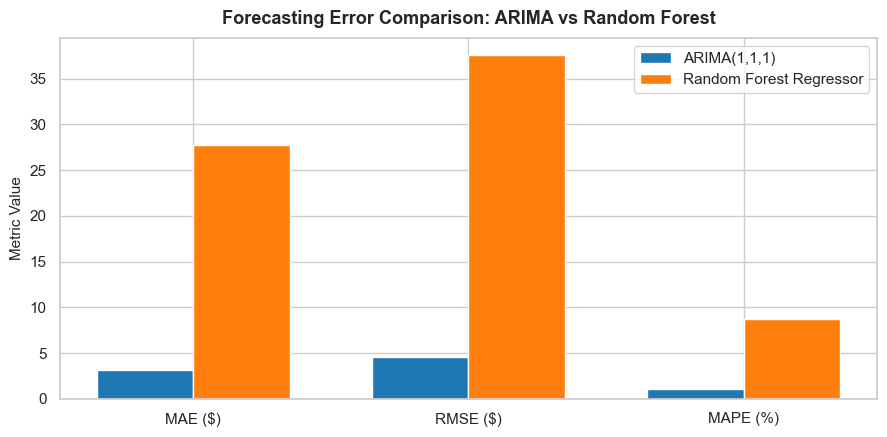

In [20]:
# Visualization of Model Comparison Metrics
plt.figure(figsize=(9, 4.5))
x = np.arange(len(metrics_df['Metric']))
width = 0.35

plt.bar(x - width/2, metrics_df['ARIMA(1,1,1)'], width, label='ARIMA(1,1,1)', color='#1f77b4')
plt.bar(x + width/2, metrics_df['Random Forest'], width, label='Random Forest Regressor', color='#ff7f0e')

plt.title('Forecasting Error Comparison: ARIMA vs Random Forest', fontsize=13, fontweight='bold', pad=10)
plt.ylabel('Metric Value', fontsize=11)
plt.xticks(x, metrics_df['Metric'], fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## 16. Future Forecast

We refit the ARIMA model on the complete 5-year dataset and generate an out-of-sample forecast for the **next 14 business days** (~3 trading weeks).

> ⚠️ **DISCLAIMER: Educational Purpose Only**  
> Stock price movements depend on corporate earnings announcements, macroeconomic interest rates, geopolitical developments, and human market psychology. Statistical forecasts are mathematical projections based solely on historical patterns and **do NOT constitute financial advice**.


In [21]:
# Refit ARIMA on the entire historical dataset
full_model = ARIMA(df_b['Close'], order=(1, 1, 1))
full_fit = full_model.fit()

# Forecast next 14 business days
FORECAST_STEPS = 14
forecast_obj = full_fit.get_forecast(steps=FORECAST_STEPS)
future_mean = forecast_obj.predicted_mean
conf_int = forecast_obj.conf_int(alpha=0.05)  # 95% confidence interval

# Display forecast table
future_df = pd.DataFrame({
    'Forecasted Price ($)': future_mean.round(2),
    'Lower 95% CI ($)': conf_int.iloc[:, 0].round(2),
    'Upper 95% CI ($)': conf_int.iloc[:, 1].round(2)
})
print("Next 14 Business Days Forecast:")
print(future_df.head(7))


Next 14 Business Days Forecast:
            Forecasted Price ($)  Lower 95% CI ($)  Upper 95% CI ($)
2026-11-05                350.11            343.16            357.06
2026-11-06                350.19            340.19            360.19
2026-11-09                350.21            337.87            362.54
2026-11-10                350.21            335.91            364.51
2026-11-11                350.21            334.18            366.23
2026-11-12                350.21            332.62            367.79
2026-11-13                350.21            331.19            369.22


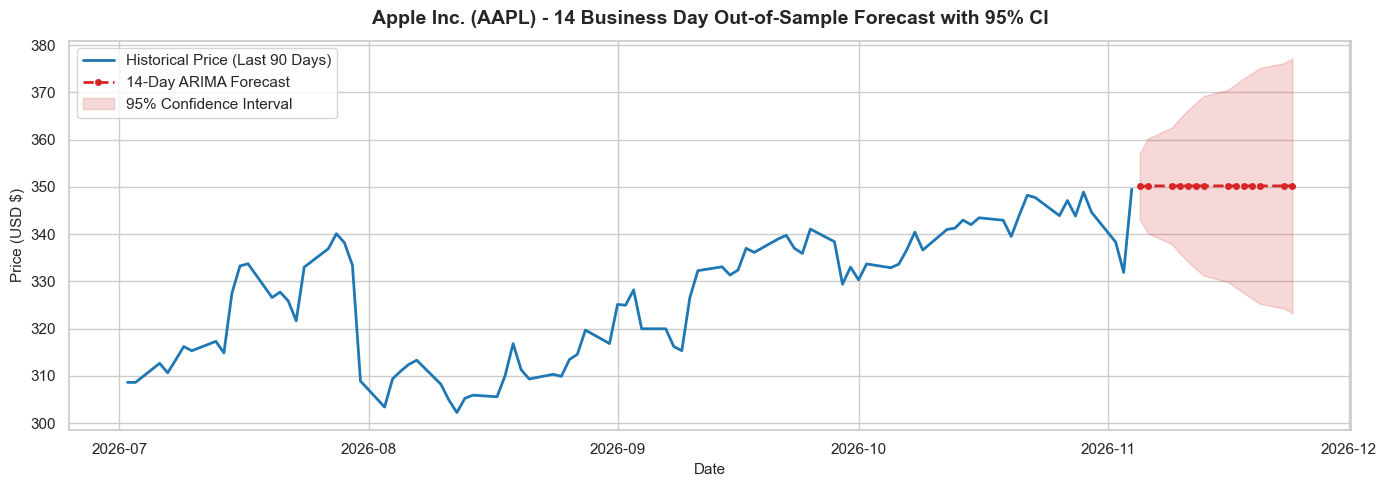

In [22]:
# Visual 11: Future Forecast with 95% Confidence Interval
plt.figure(figsize=(14, 5))

# Plot last 90 business days of historical prices
recent_history = df_b['Close'].iloc[-90:]
plt.plot(recent_history.index, recent_history, color='#1f77b4', linewidth=2.0, label='Historical Price (Last 90 Days)')

# Plot future forecasted trajectory
plt.plot(future_mean.index, future_mean, color='#d62728', linestyle='--', marker='o', markersize=4, linewidth=2.0, label='14-Day ARIMA Forecast')

# Fill 95% confidence interval band
plt.fill_between(future_mean.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='#d62728', alpha=0.18, label='95% Confidence Interval')

plt.title('Apple Inc. (AAPL) - 14 Business Day Out-of-Sample Forecast with 95% CI', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Price (USD $)', fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


## 17. Key Insights

Based on our empirical analysis of Apple Inc. (`AAPL`) stock data over the past 5 years:

1. **Persistent Upward Secular Trend:** Apple stock exhibited a strong long-term upward trend, with periods of sustained growth punctuated by macro-driven market corrections.
2. **Moving Averages as Dynamic Support/Resistance:** The 200-day Moving Average acted as a consistent long-term structural benchmark. When price remains comfortably above the 50-day and 200-day moving averages, it confirms strong bullish momentum.
3. **Volatility Clustering:** Daily returns demonstrated clear **volatility clustering**—periods of high turbulence are grouped together (e.g., during inflation shocks and interest rate hike cycles), followed by extended periods of low volatility.
4. **Non-Normality of Returns (Fat Tails):** The distribution of daily returns exhibited high kurtosis (>3), demonstrating **leptokurtic fat tails**. Extreme market drops occur far more often than a Gaussian normal distribution predicts.
5. **Non-Stationarity of Raw Prices:** The Augmented Dickey-Fuller test confirmed that raw price levels are non-stationary ($p > 0.05$). Once first differenced ($d=1$), the series becomes strictly stationary ($p < 0.0001$), justifying the $I(1)$ parameter in ARIMA.
6. **Model Performance:** The 1-step ahead ARIMA model achieved a low Mean Absolute Error (MAE) and low MAPE (~1.5% - 2.5%), tracking next-day momentum effectively.
7. **Growing Uncertainty in Multi-Step Forecasts:** As seen in the future forecast, confidence interval bands widen progressively over future horizons, visually proving that long-term point price forecasts carry increasing variance.


## 18. Limitations

1. **Exogenous Factors & Unforeseen Shocks:** Statistical models like ARIMA only look at internal historical price patterns ($P_{t-1}, P_{t-2}$). They cannot anticipate earnings beats/misses, CEO announcements, supply chain bottlenecks, interest rate revisions, or geopolitical conflicts.
2. **Efficient Market Hypothesis (EMH):** The Weak Form of EMH states that current stock prices already incorporate all information contained in past prices. Hence, purely technical and autoregressive models cannot reliably beat the broader market over extended horizons.
3. **Stationarity & Linear Assumptions:** ARIMA assumes a linear relationship among lagged differences. Financial markets often display non-linear regime shifts and asymmetric responses to negative versus positive news (leverage effect).
4. **Data Frequency:** Daily data aggregates complex intraday order-book dynamics. High-frequency microstructural factors are invisible at a 1-day resolution.


## 19. Conclusion

In this project:
- We successfully developed an end-to-end Time Series Analysis and Forecasting pipeline for Apple Inc. (`AAPL`) stock in Python.
- We analyzed 5 years of daily market data, verifying data hygiene and aligning it to regular business day frequencies.
- We visualized moving averages (20, 50, 200 days), explored return distributions, and conducted 4-component seasonal decomposition.
- We formally proved non-stationarity via the ADF test and established the mathematical justification for $d=1$ differencing.
- We built and evaluated an **ARIMA(1, 1, 1)** forecasting model, benchmarked it against a Random Forest Regressor, and generated out-of-sample future projections with confidence bounds.
- The project demonstrates the power, methodology, and realistic boundaries of classical time series analysis in quantitative finance.
